## Análise Descritiva

In [1]:
import sys
from pathlib import Path

import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.arima.model import ARIMA

sys.path.append(str(Path.cwd().parent))
from src.paths import CAMINHO_BANCO

In [2]:
conexao = sqlite3.connect(CAMINHO_BANCO)
fundamentos = pd.read_sql_query("SELECT * FROM fundamentos", conexao)
cotacoes = pd.read_sql_query("SELECT * FROM cotacoes", conexao)
conexao.close()

fundamentos.head()

,id,ticker,data,hora_coleta,pl,pvp,roe,roa,roic,margem_liquida,margem_bruta,margem_ebitda,divida_patrimonio,cagr_receita_5a,cagr_lucro_5a,data_hora_iso
0,1,PETR4,31/08/2026,13:28:17,4.13,1.17,28.26,10.66,19.72,24.88,50.85,51.15,0.76,12.83,77.68,2026-08-31 13:28:17
1,2,VALE3,31/08/2026,13:28:18,40.66,1.77,4.36,1.44,17.89,3.07,34.83,45.62,0.50,0.48,-13.86,2026-08-31 13:28:18
2,3,ITUB4,31/08/2026,13:28:18,9.24,1.90,20.51,1.46,15.88,12.17,37.58,15.21,0.00,17.38,NaN,2026-08-31 13:28:18
3,4,BBDC4,31/08/2026,13:28:20,7.31,1.00,13.65,1.01,7.16,8.88,28.05,28.47,4.32,22.38,8.33,2026-08-31 13:28:20
4,5,WEGE3,31/08/2026,13:28:21,33.07,11.12,33.63,14.42,37.97,16.52,33.43,22.61,0.27,18.49,23.11,2026-08-31 13:28:21


In [3]:
colunas_numericas = [
    "pl", "pvp", "roe", "roa", "roic",
    "margem_liquida", "margem_bruta", "margem_ebitda",
    "divida_patrimonio", "cagr_receita_5a", "cagr_lucro_5a"
]

df_fund = fundamentos.set_index("ticker")[colunas_numericas]
df_fund

,pl,pvp,roe,roa,roic,margem_liquida,margem_bruta,margem_ebitda,divida_patrimonio,cagr_receita_5a,cagr_lucro_5a
ticker,,,,,,,,,,,
PETR4,4.13,1.17,28.26,10.66,19.72,24.88,50.85,51.15,0.76,12.83,77.68
VALE3,40.66,1.77,4.36,1.44,17.89,3.07,34.83,45.62,0.50,0.48,-13.86
ITUB4,9.24,1.90,20.51,1.46,15.88,12.17,37.58,15.21,0.00,17.38,NaN
BBDC4,7.31,1.00,13.65,1.01,7.16,8.88,28.05,28.47,4.32,22.38,8.33
WEGE3,33.07,11.12,33.63,14.42,37.97,16.52,33.43,22.61,0.27,18.49,23.11
BBAS3,8.68,0.62,7.15,0.64,4.29,5.08,31.66,21.57,5.13,26.49,4.77
BBSE3,8.62,7.13,82.77,41.12,37.98,NaN,NaN,NaN,0.36,NaN,18.55
FIQE3,9.02,1.56,17.26,6.63,13.56,16.86,51.23,36.66,0.86,32.89,32.87
ISAE4,6.43,0.85,13.18,5.97,8.01,28.20,46.36,43.93,0.80,20.55,-5.79


In [4]:
df_fund.describe().T

,count,mean,std,min,25%,50%,75%,max
pl,50.0,13.788200,11.991164,4.13,7.4875,8.955,9.660,41.80
pvp,50.0,2.925400,3.350399,0.62,1.0250,1.590,1.925,11.59
roe,50.0,23.960000,21.530626,4.36,13.1800,18.045,28.260,82.77
roa,50.0,9.815000,11.751495,0.64,1.4400,6.300,14.420,41.12
roic,50.0,16.267000,12.441294,0.21,7.1600,14.720,19.720,37.98
margem_liquida,45.0,36.406667,63.289209,3.07,8.8800,16.520,24.880,212.00
margem_bruta,45.0,37.642222,9.254639,24.79,31.6600,34.830,46.360,51.23
margem_ebitda,45.0,31.817778,12.271688,15.21,21.5700,28.470,43.930,51.15
divida_patrimonio,50.0,1.311000,1.755862,0.00,0.2700,0.630,0.860,5.13
cagr_receita_5a,45.0,17.611111,9.373572,0.48,12.8300,18.490,22.380,32.89


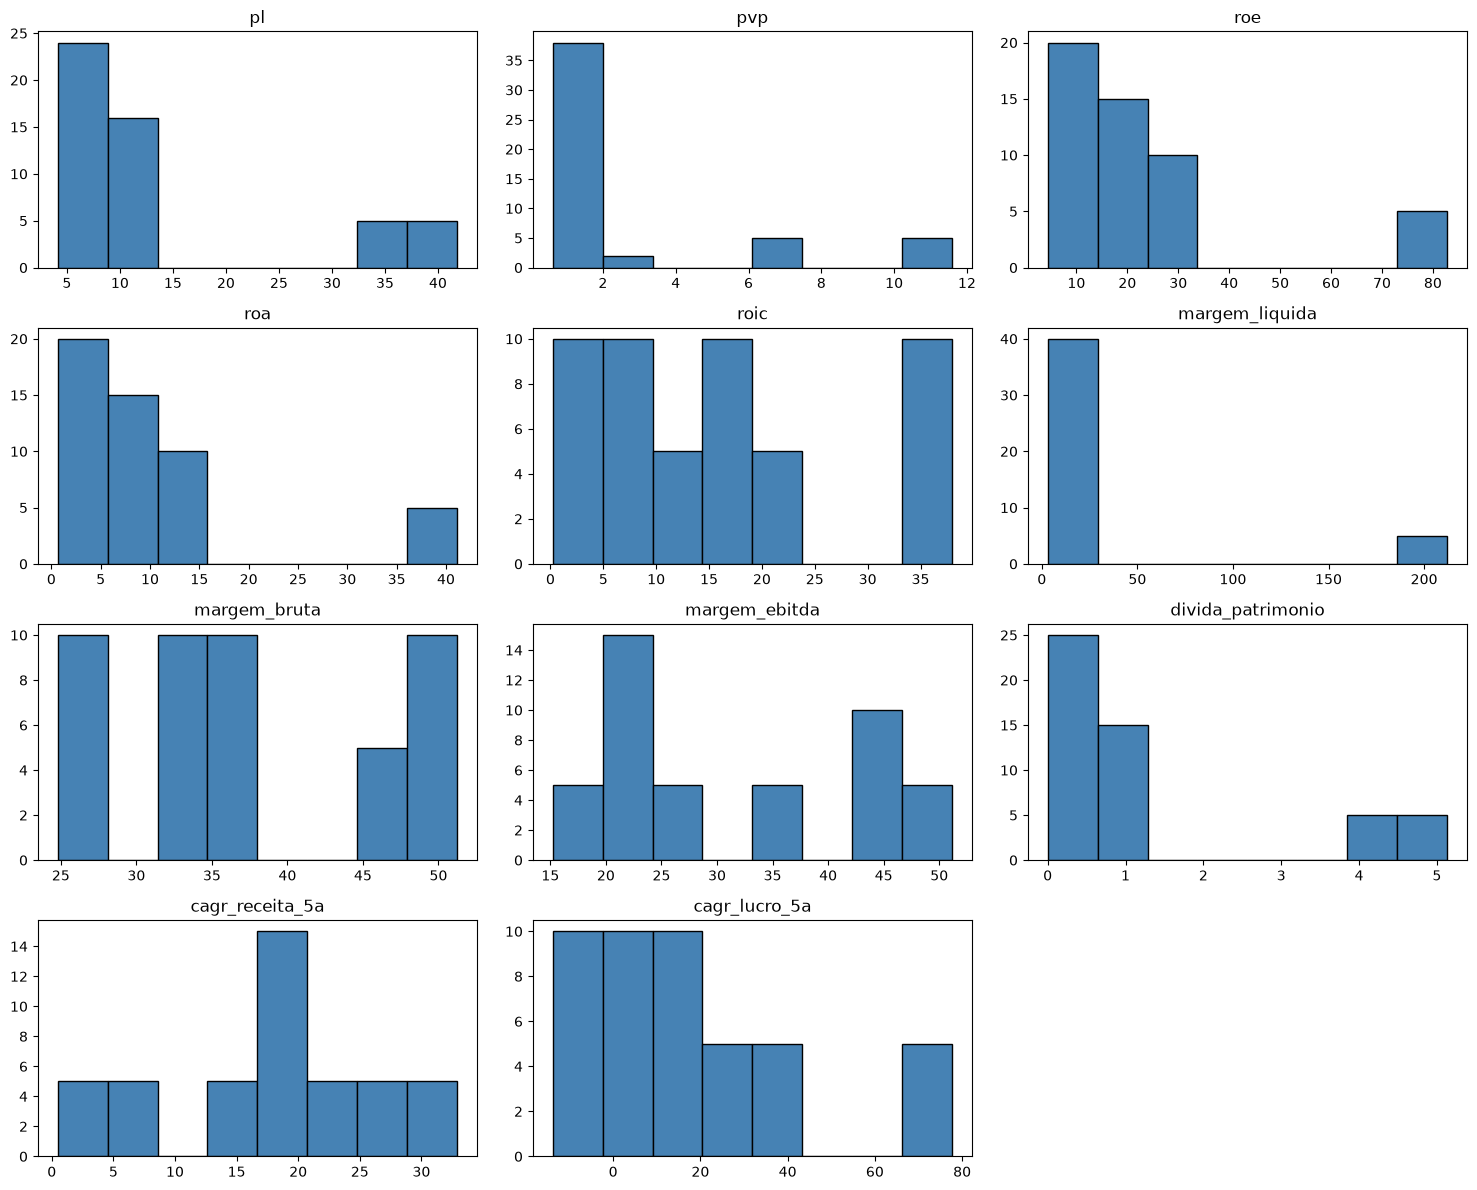

In [5]:
fig, eixos = plt.subplots(4, 3, figsize=(15, 12))
eixos = eixos.flatten()

for i, coluna in enumerate(colunas_numericas):
    eixos[i].hist(df_fund[coluna].dropna(), bins=8, color="steelblue", edgecolor="black")
    eixos[i].set_title(coluna)

for j in range(len(colunas_numericas), len(eixos)):
    fig.delaxes(eixos[j])

plt.tight_layout()
plt.show()

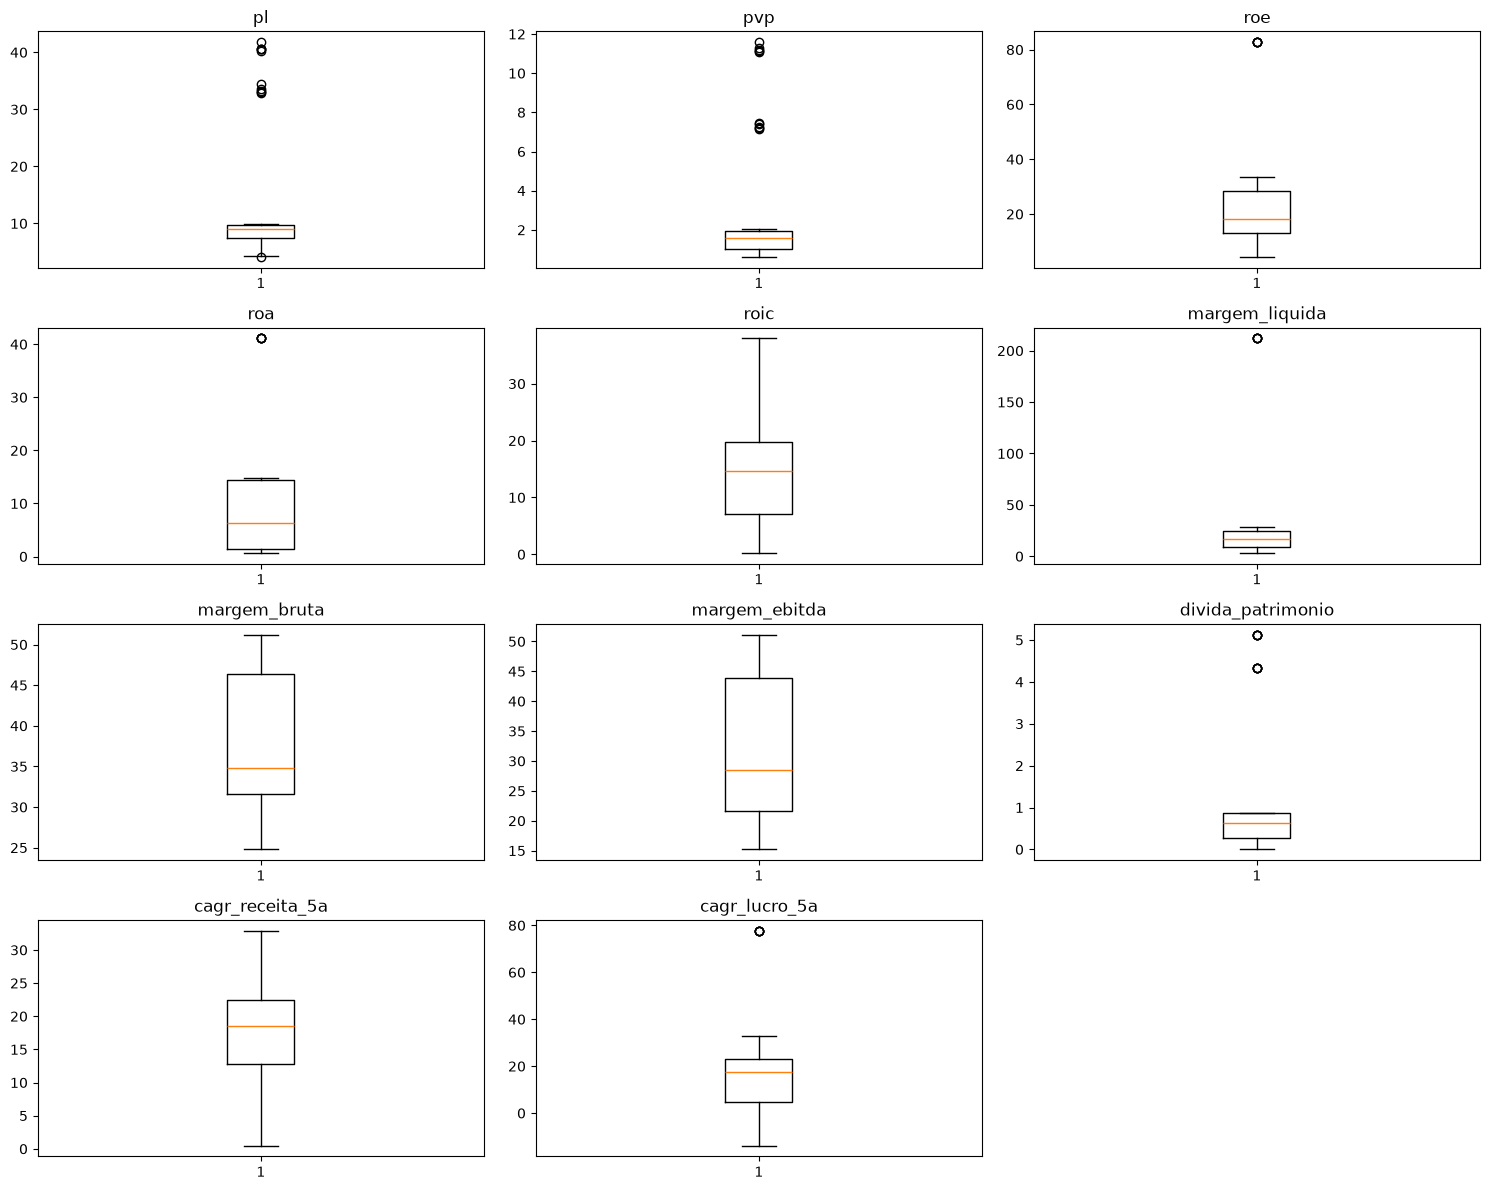

In [6]:
fig, eixos = plt.subplots(4, 3, figsize=(15, 12))
eixos = eixos.flatten()

for i, coluna in enumerate(colunas_numericas):
    eixos[i].boxplot(df_fund[coluna].dropna())
    eixos[i].set_title(coluna)

for j in range(len(colunas_numericas), len(eixos)):
    fig.delaxes(eixos[j])

plt.tight_layout()
plt.show()

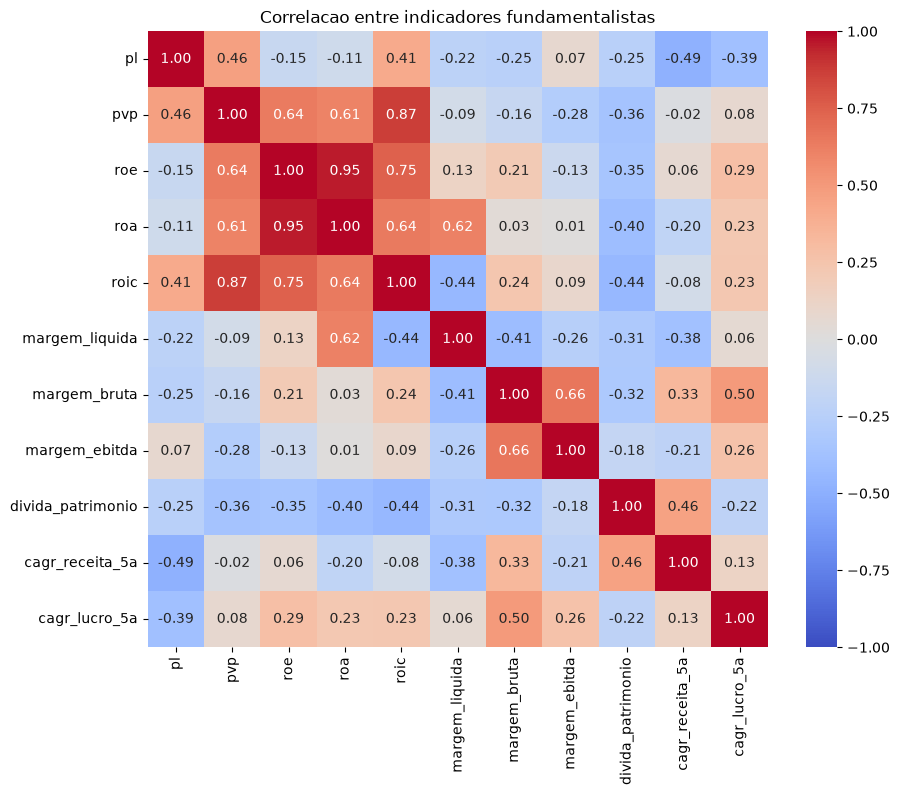

In [7]:
matriz_correlacao = df_fund.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(matriz_correlacao, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlacao entre indicadores fundamentalistas")
plt.show()

In [8]:
df_pca_input = df_fund.fillna(df_fund.median())

scaler = StandardScaler()
dados_padronizados = scaler.fit_transform(df_pca_input)

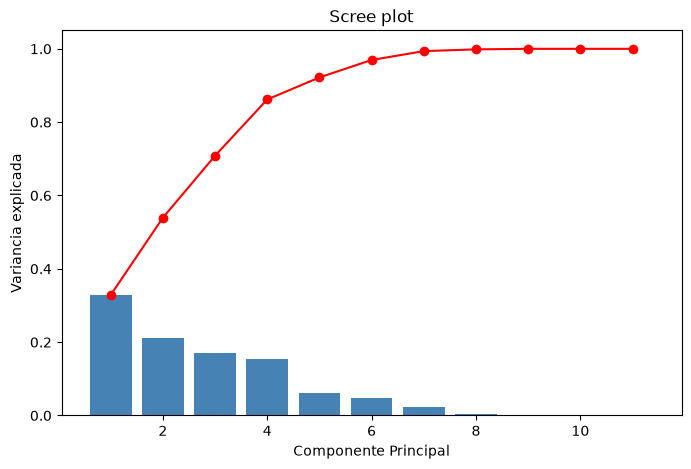

In [9]:
pca = PCA()
componentes = pca.fit_transform(dados_padronizados)

variancia_explicada = pca.explained_variance_ratio_

plt.figure(figsize=(8, 5))
plt.bar(range(1, len(variancia_explicada) + 1), variancia_explicada, color="steelblue")
plt.plot(range(1, len(variancia_explicada) + 1), variancia_explicada.cumsum(), color="red", marker="o")
plt.xlabel("Componente Principal")
plt.ylabel("Variancia explicada")
plt.title("Scree plot")
plt.show()

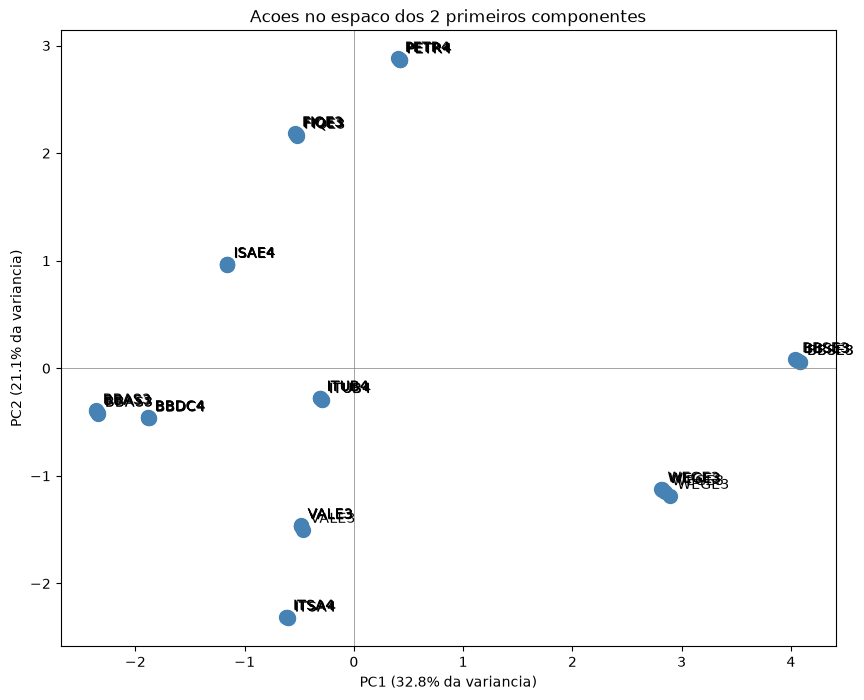

In [10]:
plt.figure(figsize=(10, 8))
plt.scatter(componentes[:, 0], componentes[:, 1], color="steelblue", s=100)

for i, ticker in enumerate(df_fund.index):
    plt.annotate(ticker, (componentes[i, 0], componentes[i, 1]), fontsize=10, xytext=(5, 5), textcoords="offset points")

plt.xlabel(f"PC1 ({variancia_explicada[0]*100:.1f}% da variancia)")
plt.ylabel(f"PC2 ({variancia_explicada[1]*100:.1f}% da variancia)")
plt.title("Acoes no espaco dos 2 primeiros componentes")
plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)
plt.show()

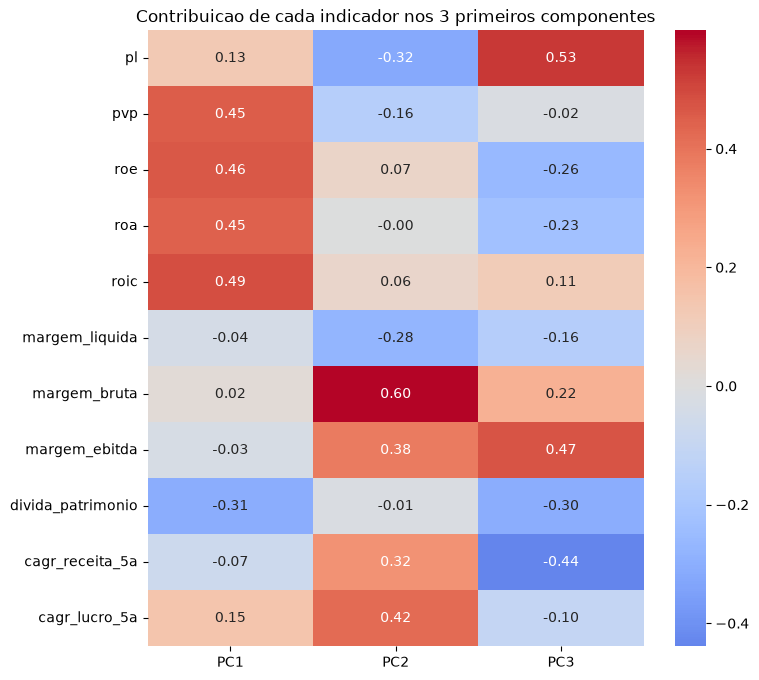

In [11]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(pca.n_components_)],
    index=colunas_numericas
)

plt.figure(figsize=(8, 8))
sns.heatmap(loadings[["PC1", "PC2", "PC3"]], annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Contribuicao de cada indicador nos 3 primeiros componentes")
plt.show()

## Análise de Séries Temporais

In [12]:
cotacoes["timestamp"] = pd.to_datetime(cotacoes["data"] + " " + cotacoes["hora_coleta"], format="%d/%m/%Y %H:%M:%S")
cotacoes = cotacoes.sort_values("timestamp")

cotacoes.groupby("ticker")["timestamp"].count().sort_values(ascending=False)

ticker
ITUB4     31
PETR4     31
VALE3     31
WEGE3     25
BBDC4     25
FIQE3     24
BTCI11    24
BBSE3     24
BBAS3     24
ITSA4     24
ISAE4     24
GARE11    24
MXRF11    24
Name: timestamp, dtype: int64

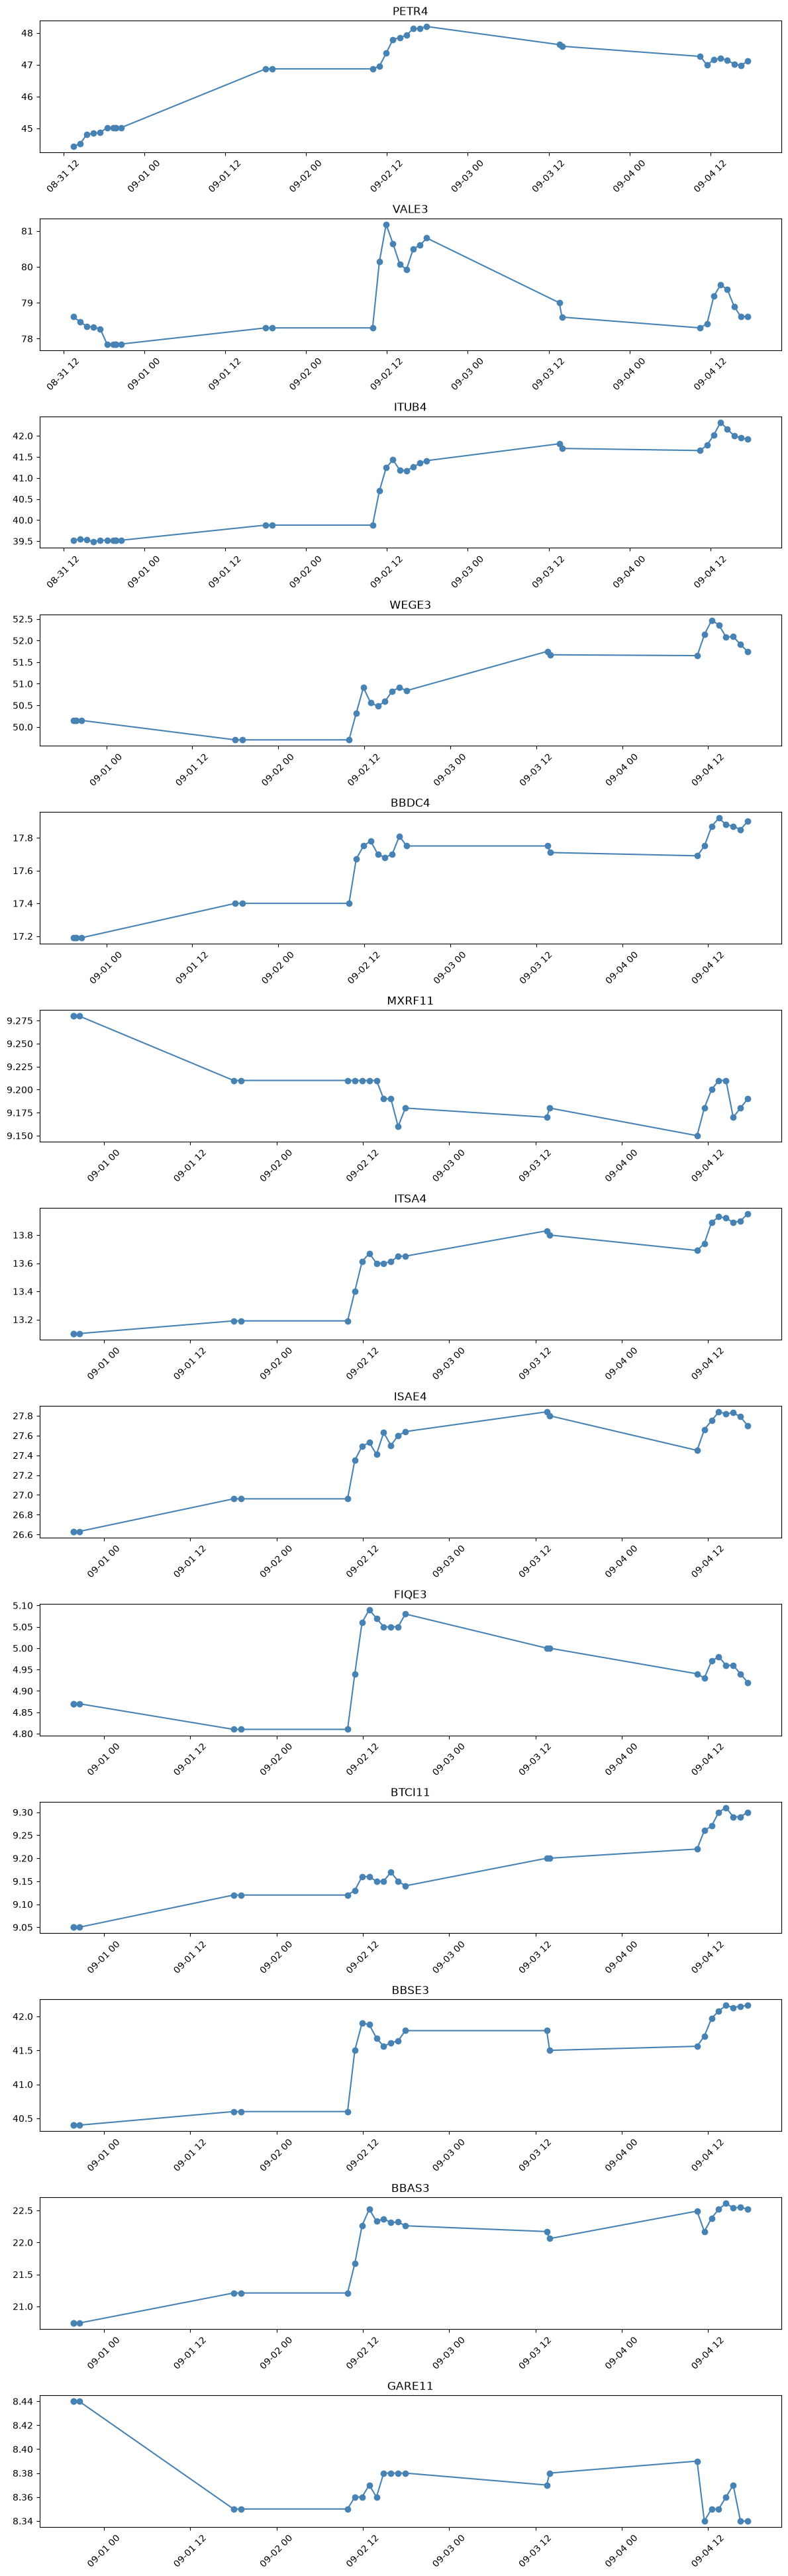

In [13]:
tickers = cotacoes["ticker"].unique()
n_tickers = len(tickers)

fig, eixos = plt.subplots(n_tickers, 1, figsize=(12, 3 * n_tickers), sharex=False)

for i, ticker in enumerate(tickers):
    dados_ticker = cotacoes[cotacoes["ticker"] == ticker]
    eixos[i].plot(dados_ticker["timestamp"], dados_ticker["preco"], marker="o", color="steelblue")
    eixos[i].set_title(ticker)
    eixos[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [14]:
ticker_foco = cotacoes.groupby("ticker")["timestamp"].count().idxmax()
print(f"Ticker escolhido para analise detalhada: {ticker_foco}")

serie = cotacoes[cotacoes["ticker"] == ticker_foco].set_index("timestamp")["preco"]
serie

Ticker escolhido para analise detalhada: ITUB4


timestamp
2026-08-31 13:28:16    39.52
2026-08-31 14:28:26    39.55
2026-08-31 15:28:32    39.53
2026-08-31 16:28:38    39.48
2026-08-31 17:28:43    39.52
2026-08-31 18:28:49    39.52
2026-08-31 19:23:14    39.52
2026-08-31 19:43:39    39.52
2026-08-31 19:44:38    39.52
2026-08-31 20:32:48    39.52
2026-09-01 18:00:47    39.88
2026-09-01 19:01:12    39.88
2026-09-02 09:52:17    39.88
2026-09-02 10:52:40    40.69
2026-09-02 11:52:55    41.24
2026-09-02 12:53:10    41.43
2026-09-02 13:53:25    41.19
2026-09-02 14:53:40    41.17
2026-09-02 15:53:55    41.26
2026-09-02 16:54:10    41.35
2026-09-02 17:54:25    41.41
2026-09-03 13:33:58    41.81
2026-09-03 13:58:25    41.70
2026-09-04 10:28:32    41.65
2026-09-04 11:28:56    41.78
2026-09-04 12:29:11    42.02
2026-09-04 13:29:27    42.32
2026-09-04 14:29:43    42.16
2026-09-04 15:29:58    42.00
2026-09-04 16:30:15    41.95
2026-09-04 17:30:31    41.92
Name: preco, dtype: float64

In [15]:
from statsmodels.tsa.stattools import adfuller

resultado_adf = adfuller(serie.dropna())

print(f"Estatistica ADF: {resultado_adf[0]:.4f}")
print(f"p-valor: {resultado_adf[1]:.4f}")
print("Valores criticos:", resultado_adf[4])

if resultado_adf[1] < 0.05:
    print("\nConclusao: serie parece ESTACIONARIA (rejeita H0)")
else:
    print("\nConclusao: serie parece NAO estacionaria (nao rejeita H0)")

Estatistica ADF: -0.6542
p-valor: 0.8583
Valores criticos: {'1%': np.float64(-3.6699197407407405), '5%': np.float64(-2.9640707407407407), '10%': np.float64(-2.621171111111111)}

Conclusao: serie parece NAO estacionaria (nao rejeita H0)


C:\Users\usuario\AppData\Local\Temp\ipykernel_2900\7477919.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_adf = adfuller(serie.dropna())


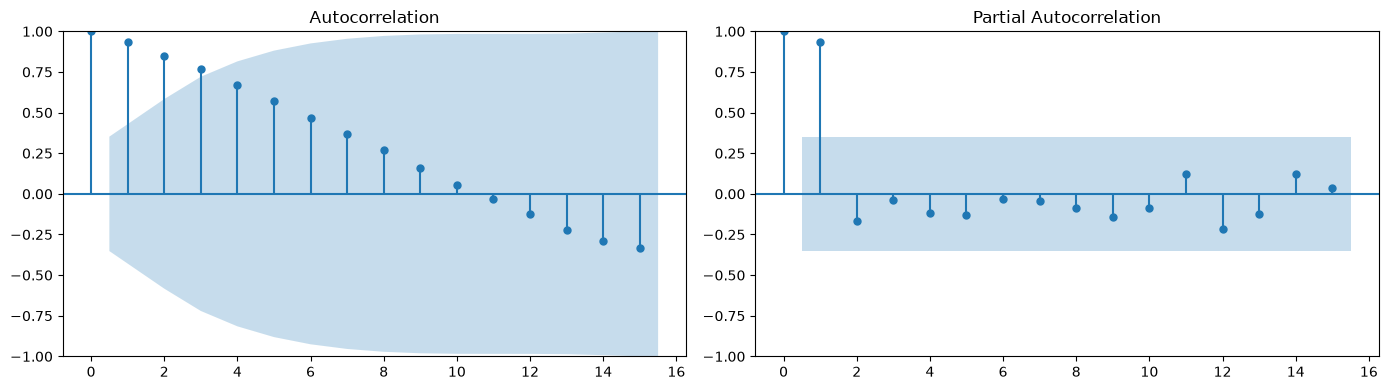

In [16]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, (eixo1, eixo2) = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(serie.dropna(), ax=eixo1)
plot_pacf(serie.dropna(), ax=eixo2)
plt.tight_layout()
plt.show()

In [17]:
import itertools
import warnings
warnings.filterwarnings("ignore")

valores_p = range(0, 3)
valores_d = range(0, 2)
valores_q = range(0, 3)

resultados = []

for p, d, q in itertools.product(valores_p, valores_d, valores_q):
    try:
        modelo = ARIMA(serie, order=(p, d, q))
        ajuste = modelo.fit()
        resultados.append({"p": p, "d": d, "q": q, "aic": ajuste.aic})
    except Exception:
        continue

df_resultados = pd.DataFrame(resultados).sort_values("aic")
df_resultados.head(10)

,p,d,q,aic
4,0,1,1,-4.322965
9,1,1,0,-2.997025
5,0,1,2,-2.328617
10,1,1,1,-2.327778
15,2,1,0,-2.088904
3,0,1,0,-0.777009
11,1,1,2,-0.678573
16,2,1,1,-0.372713
17,2,1,2,1.244860
7,1,0,1,2.249875
